# Shared setup and data loading

This notebook uses the **incident-level cleaned dataset**. Each row should represent one unique `Incident ID`, not one offence record. Multi-valued offence fields are stored as strings separated by ` | `.

The analysis is descriptive and exploratory, in line with the CI7340 brief. The coursework requires 10 research questions and 20 question-linked visualisations overall; this notebook contributes two visualisations to its assigned research question.

**Input:** `crime_dataset_incident_level_cleaned.csv`

> Run the notebook from top to bottom. Keep the original cleaned dataset unchanged.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from collections import Counter
from scipy.stats import chi2_contingency, spearmanr, kruskal
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["figure.dpi"] = 120

In [2]:
df = pd.read_csv("crime_dataset_incident_level_cleaned.csv", low_memory=False)

In [3]:
print(f"Rows: {len(df):,}")
print(f"Columns: {len(df.columns):,}")
print(f"Unique Incident IDs: {df['Incident ID'].nunique():,}")
print(f"Duplicate Incident IDs: {df['Incident ID'].duplicated().sum():,}")

Rows: 467,601
Columns: 50
Unique Incident IDs: 467,601
Duplicate Incident IDs: 0


## Data integrity check

The incident-level unit of analysis is essential here. The following check confirms that each `Incident ID` appears once. If duplicate IDs are found, stop and resolve the issue rather than silently dropping rows.

In [4]:
assert df["Incident ID"].is_unique, (
    "Incident ID is not unique. This file is not one-row-per-incident."
)

## Parse multi-valued fields

During incident-level aggregation, offence labels were retained as pipe-separated unique values. This helper converts those strings into lists and removes empty or duplicate labels. It supports both single-offence and multi-offence incidents.

In [5]:
def split_multi_value(value):
    if pd.isna(value):
        return []
    return list(dict.fromkeys(
        item.strip() for item in str(value).split("|") if item.strip()
    ))

# H3 — Offence multiplicity and victim-offence burden

## Research question

**Is the number of offence records within an incident associated with the incident's aggregated victim-offence count?**

### Analytical framing
- **Unit of analysis:** one unique `Incident ID`.
- **Explanatory variable (X):** `Total_Offence_Records`, the number of offence records linked to the incident.
- **Outcome (Y):** `Victims`, aggregated across the offence records linked to that incident.
- **Expected evidence:** the distribution of aggregated victim-offence counts across offence-count groups and the strength/direction of the monotonic relationship.

**Important measurement caveat:** `Victims` in the incident-level dataset is a sum of offence-level victim counts. It is a victim–offence association total, not a count of distinct people. The same person may be counted for more than one offence in an incident, and society can be the NIBRS victim for some offences. The analysis must therefore use the phrase *aggregated victim-offence count*, not “unique victims”.

## 1. Validate variables and prepare analysis fields

The incident-level dataset should have one row per incident. The two numeric fields must be present and non-negative. The analysis retains valid observations and does not remove high victim counts merely because they are rare.

In [6]:
required = ["Incident ID", "Total_Offence_Records", "Victims"]
missing = [c for c in required if c not in df.columns]
if missing:
    raise KeyError(f"Missing required columns: {missing}")

In [7]:
analysis = df[required].copy()
analysis["Total_Offence_Records"] = pd.to_numeric(
    analysis["Total_Offence_Records"], errors="coerce"
)
analysis["Victims"] = pd.to_numeric(analysis["Victims"], errors="coerce")

In [8]:
analysis = analysis.dropna(subset=["Total_Offence_Records", "Victims"])
analysis = analysis.loc[
    analysis["Total_Offence_Records"].gt(0)
    & analysis["Victims"].ge(0)
].copy()
analysis["Total_Offence_Records"] = analysis["Total_Offence_Records"].astype(int)

## 2. Descriptive statistics

The distribution is likely to be right-skewed: most incidents have one offence record and one victim-offence association. Median and interquartile range are therefore reported alongside the mean and standard deviation. These summaries are calculated separately for each offence-count group.

In [9]:
h3_summary = (
    analysis.groupby("Total_Offence_Records")["Victims"]
    .agg(
        Incident_Count="size",
        Mean="mean",
        Median="median",
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75),
        Maximum="max"
    )
)
h3_summary["IQR"] = h3_summary["Q3"] - h3_summary["Q1"]
display(h3_summary)

,Incident_Count,Mean,Median,Q1,Q3,Maximum,IQR
Total_Offence_Records,,,,,,,
1,433852,1.019885,1.0,1.0,1.0,22,0.0
2,28603,2.059924,2.0,2.0,2.0,9,0.0
3,3935,3.127319,3.0,3.0,3.0,9,0.0
4,918,4.209150,4.0,4.0,4.0,11,0.0
5,219,5.146119,5.0,5.0,5.0,9,0.0
6,50,6.500000,6.0,6.0,6.0,12,0.0
7,18,7.111111,7.0,7.0,7.0,8,0.0
8,4,8.000000,8.0,8.0,8.0,8,0.0
9,2,9.000000,9.0,9.0,9.0,9,0.0


In [10]:
overall_spearman = spearmanr(
    analysis["Total_Offence_Records"],
    analysis["Victims"],
    nan_policy="omit"
)
print(f"Spearman correlation: {overall_spearman.statistic:.4f}")
print(f"p-value: {overall_spearman.pvalue:.4g}")

Spearman correlation: 0.9000
p-value: 0


## Visualisation 1 — Distribution of aggregated victim-offence counts by offence-count group

A boxplot compares the median, interquartile range and outliers for each number-of-offences group. The x-axis is categorical because offence-count groups are discrete. The chart is restricted to groups with at least 30 incidents for readability; the descriptive table above retains all groups.

In [11]:
group_sizes = analysis["Total_Offence_Records"].value_counts()
display(group_sizes.sort_index().rename("Incident count").to_frame())

,Incident count
Total_Offence_Records,
1,433852
2,28603
3,3935
4,918
5,219
6,50
7,18
8,4
9,2


In [12]:
display_groups = group_sizes[group_sizes >= 30].index
plot_data = analysis[analysis["Total_Offence_Records"].isin(display_groups)].copy()

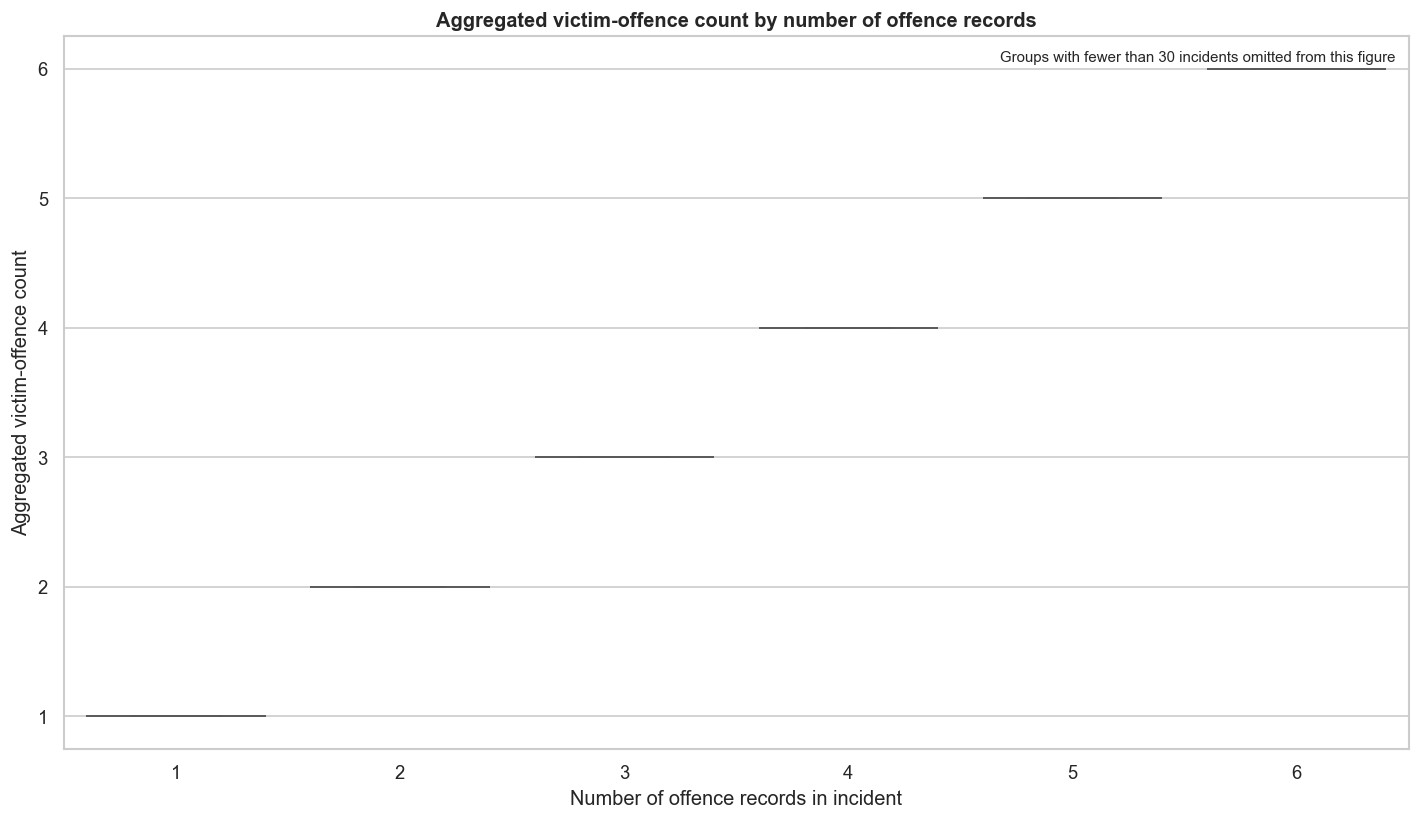

In [13]:
fig, ax = plt.subplots(figsize=(12, 7))
sns.boxplot(
    data=plot_data,
    x="Total_Offence_Records",
    y="Victims",
    color="#72B7B2",
    showfliers=False,
    ax=ax
)
ax.set_title("Aggregated victim-offence count by number of offence records", weight="bold")
ax.set_xlabel("Number of offence records in incident")
ax.set_ylabel("Aggregated victim-offence count")
ax.text(
    0.99, 0.98,
    "Groups with fewer than 30 incidents omitted from this figure",
    transform=ax.transAxes, ha="right", va="top", fontsize=9
)
plt.tight_layout()
plt.show()

**How to interpret Figure 1:** Compare medians and interquartile ranges across offence-count groups. An upward pattern would indicate that incidents with more offence records tend to have higher aggregated victim-offence counts. The plot suppresses outlier markers for legibility; the underlying values remain in the data and summary table.

## Visualisation 2 — Median and interquartile range across offence-count groups

A median-with-IQR plot is used as a second view because it is less affected by extreme values than the mean. It makes the central tendency and spread of the aggregated victim-offence count explicit, while displaying the number of incidents supporting each group.

In [14]:
plot_summary = h3_summary.loc[display_groups].copy().reset_index()

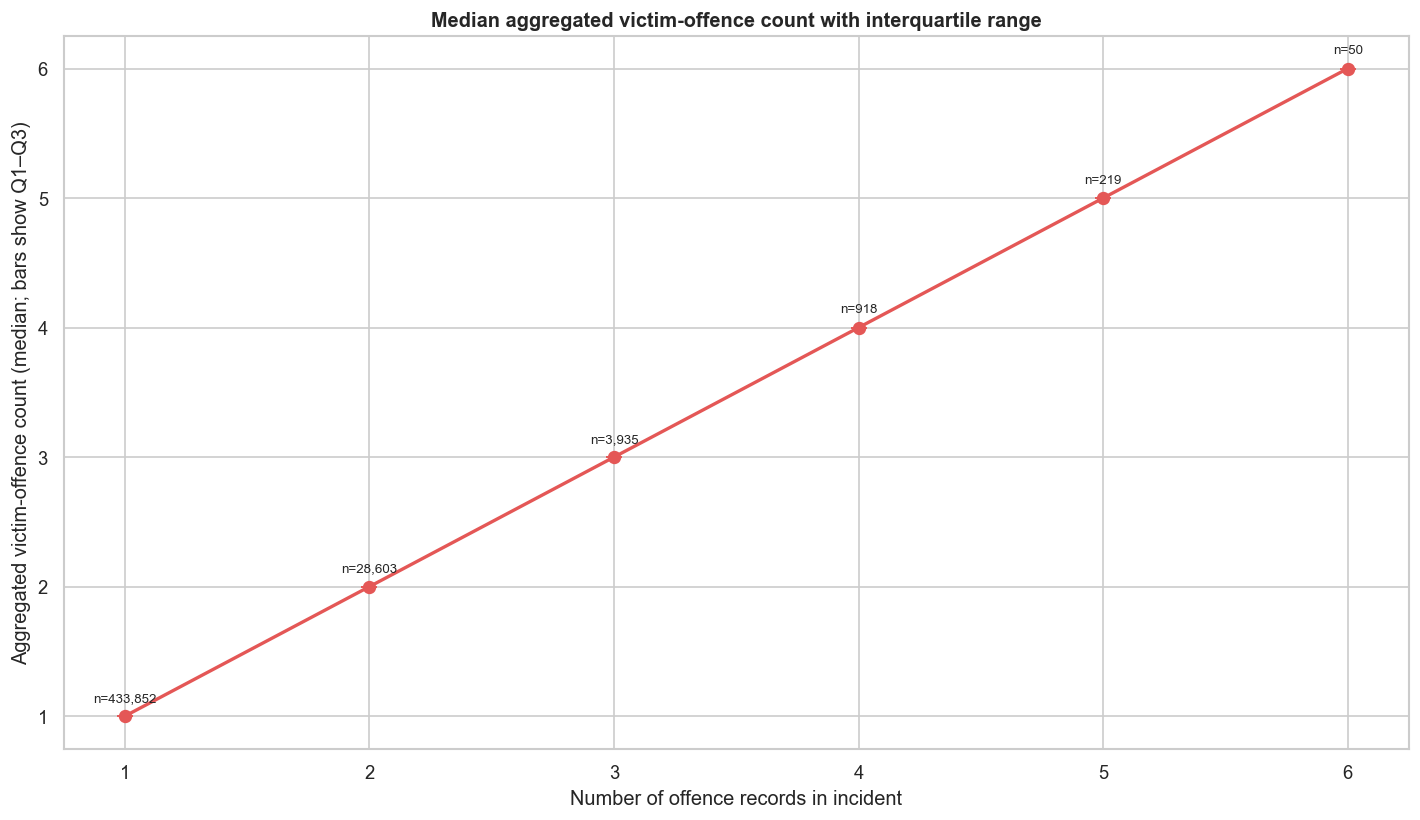

In [15]:
fig, ax = plt.subplots(figsize=(12, 7))
x = plot_summary["Total_Offence_Records"].to_numpy()
median = plot_summary["Median"].to_numpy()
lower = (plot_summary["Median"] - plot_summary["Q1"]).to_numpy()
upper = (plot_summary["Q3"] - plot_summary["Median"]).to_numpy()

ax.errorbar(
    x, median,
    yerr=np.vstack([lower, upper]),
    fmt="o-",
    capsize=5,
    linewidth=2,
    markersize=7,
    color="#E45756"
)
for xi, yi, count in zip(x, median, plot_summary["Incident_Count"]):
    ax.annotate(f"n={count:,}", (xi, yi), xytext=(0, 9),
                textcoords="offset points", ha="center", fontsize=8)
ax.set_title("Median aggregated victim-offence count with interquartile range", weight="bold")
ax.set_xlabel("Number of offence records in incident")
ax.set_ylabel("Aggregated victim-offence count (median; bars show Q1–Q3)")
ax.set_xticks(x)
plt.tight_layout()
plt.show()

**How to interpret Figure 2:** A rising median indicates that the typical aggregated victim-offence count increases with offence multiplicity. Wider IQR bars indicate greater variation within that offence-count group. Always read the `n` labels: estimates for rare groups are less stable.

## Optional non-parametric group comparison

A Kruskal–Wallis test compares the distributions of aggregated victim-offence counts across offence-count groups. It is used instead of a one-way ANOVA because the outcome is highly discrete and skewed. The test only indicates whether at least one group distribution differs; it does not identify which groups differ. The descriptive effect pattern remains primary for this exploratory coursework.

In [16]:
kruskal_groups = [
    values["Victims"].to_numpy()
    for _, values in analysis.groupby("Total_Offence_Records")
    if len(values) >= 30
]
if len(kruskal_groups) >= 2:
    kw_stat, kw_p = kruskal(*kruskal_groups)
    print(f"Kruskal-Wallis statistic: {kw_stat:.4f}")
    print(f"p-value: {kw_p:.4g}")
else:
    print("Not enough offence-count groups with at least 30 incidents for the test.")

Kruskal-Wallis statistic: 378729.7649
p-value: 0


## Conclusion and limitations

Use the figures, descriptive table and optional tests to determine whether the evidence supports an association.

- Spearman's rank correlation summarises the direction and strength of a monotonic relationship.
- The boxplot and median-IQR plot show how the distribution changes across offence-count groups.
- A high aggregated victim-offence count does not necessarily represent the same number of distinct people.
- `Victims` may include society as the victim for offences against society.
- The relationship is partly expected by construction because both variables are derived from the offence records linked to an incident. A multi-offence incident has more opportunities to accumulate victim-offence counts. This is a descriptive association, not evidence that recording more offences causes more people to be victimised.
- Rare groups (especially incidents with 6–9 offence records) have small sample sizes and should not be over-interpreted.

**Suggested reporting sentence:** “The incident-level analysis showed a [weak/moderate/strong] positive/negative association between offence-record count and aggregated victim-offence count (Spearman’s ρ = …). However, this measure represents victim–offence associations rather than distinct individuals, and the relationship is partly mechanically linked to how the variables are constructed.”